# 1. Introduction to Task-Specific Auto Classes

Hugging Face provides different Auto Classes to load pre-trained models based on the task we want to perform.

Different NLP tasks require different model architectures and output formats.

For example:

- Text classification requires a classification model.
- Named Entity Recognition (NER) requires a token classification model.
- Text generation requires a causal language model.
- Translation requires a sequence-to-sequence model.

Instead of manually selecting the model architecture, we can use the appropriate Auto Class.

**Why do we need Task-Specific Auto Classes?**

1. They automatically identify the suitable model architecture.
2. They load pre-trained model weights.
3. They provide task-specific output layers.
4. They make model loading easier.
5. They help perform different NLP tasks using a consistent approach.

**Important:** `AutoModel` loads the base model, whereas task-specific Auto Classes load models with additional task-specific layers when required.

# 2. AutoModel

**What is AutoModel?**

`AutoModel` is a Hugging Face class used to load the base architecture of a pre-trained model.

It provides the main model representations without adding a task-specific classification or generation head.

**Purpose:**

- Load a pre-trained base model.
- Extract contextual information from input text.
- Generate hidden representations.
- Use the model as a foundation for other NLP tasks.

**Example Task:**

Text representation and feature extraction.

**Model:**

`distilbert/distilbert-base-uncased`

**Input:**

A sentence converted into token IDs using a tokenizer.

**Output:**

- `last_hidden_state`: Contextual representation of every input token.
- `hidden_states`: Representations from different model layers, when requested.
- `attentions`: Attention weights, when requested.

**Important:** AutoModel does not directly predict sentiment or generate text. It provides the base model representations.

In [1]:

from transformers import AutoTokenizer, AutoModel
import torch

model_name = "distilbert/distilbert-base-uncased"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load base model
model = AutoModel.from_pretrained(model_name)

# Input text
text = "Hugging Face makes NLP easier."

# Tokenization
inputs = tokenizer(text, return_tensors="pt")

# Perform inference
with torch.no_grad():
    outputs = model(**inputs)

# Inspect output
print("Output shape:", outputs.last_hidden_state.shape)
print("Output:", outputs.last_hidden_state)


Output shape: torch.Size([1, 9, 768])
Output: tensor([[[-0.3067, -0.1722,  0.1073,  ..., -0.2979,  0.1151,  0.3882],
         [ 0.1305, -0.0092,  0.3600,  ..., -0.1379,  0.2732,  0.3249],
         [ 0.0881, -0.0120,  0.2688,  ..., -0.4210,  0.1681,  0.2790],
         ...,
         [-0.6407, -0.2089,  0.2171,  ..., -0.1155, -0.0105, -0.2603],
         [ 0.3176, -0.0141, -0.4901,  ...,  0.2195, -0.4695, -0.3913],
         [ 0.5854,  0.3339, -0.1929,  ...,  0.1463, -0.6261, -0.2589]]])


# 3. AutoModelForSequenceClassification

**What is AutoModelForSequenceClassification?**

`AutoModelForSequenceClassification` is a Hugging Face class used to classify an entire input text into one or more predefined categories.

It loads a pre-trained model with an additional classification head.

**Purpose:**

- Classify text into predefined categories.
- Perform sentiment analysis.
- Identify positive or negative reviews.
- Classify news articles into different categories.
- Perform text classification tasks.

**Example Tasks:**

- Sentiment Analysis
- Spam Detection
- News Classification
- Emotion Classification

**Model:**

`distilbert/distilbert-base-uncased-finetuned-sst-2-english`

**Input:**

A sentence or paragraph converted into token IDs.

**Output:**

- `logits`: Raw classification scores produced by the model.
- `predicted_class`: The class with the highest score.
- `probabilities`: Confidence scores calculated using Softmax.

**Important:** This class predicts a category for the entire input text, not a separate category for every token.

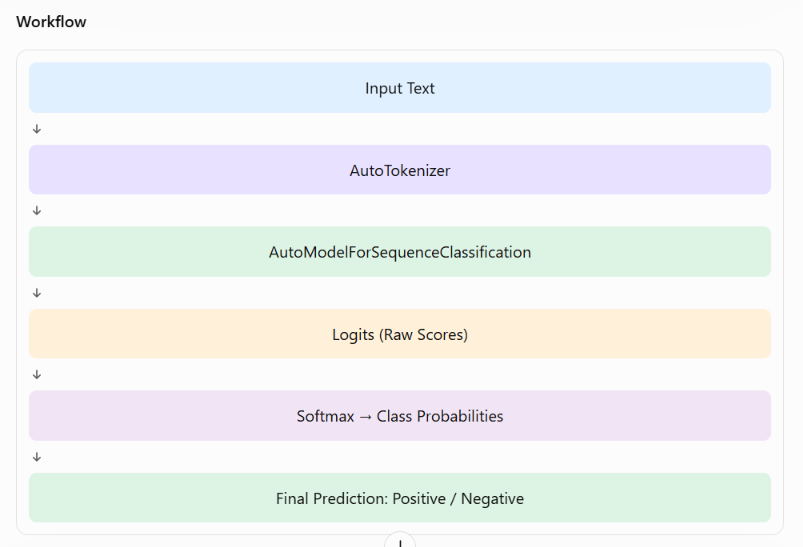

In [2]:

from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load classification model
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Input text
text = "I really enjoyed learning Hugging Face."

# Tokenization
inputs = tokenizer(text, return_tensors="pt")

# Perform inference
with torch.no_grad():
    outputs = model(**inputs)

# Get raw scores
logits = outputs.logits

# Convert scores into probabilities
probabilities = torch.softmax(logits, dim=-1)

# Get predicted class
predicted_class = torch.argmax(probabilities, dim=-1).item()

# Get class label
label = model.config.id2label[predicted_class]

print("Logits:", logits)
print("Probabilities:", probabilities)
print("Predicted Class:", label)


Logits: tensor([[-4.2030,  4.5018]])
Probabilities: tensor([[1.6576e-04, 9.9983e-01]])
Predicted Class: POSITIVE


In [ ]:
Expected output explanation
The model produces two classification scores because this model supports two sentiment classes.
Output	Meaning
Logits	Raw classification scores
Probabilities	Scores converted into probabilities
Predicted Class	POSITIVE or NEGATIVE

Example output (probabilities will depend on inference):

# 4. AutoModelForTokenClassification

**What is AutoModelForTokenClassification?**

`AutoModelForTokenClassification` is a Hugging Face class used to classify individual tokens in an input sentence.

Unlike sequence classification, which predicts one category for the entire sentence, token classification predicts a label for each token.

**Purpose:**

- Assign labels to individual tokens.
- Identify names of people.
- Identify organizations.
- Identify locations.
- Perform Named Entity Recognition (NER).
- Perform part-of-speech tagging.

**Example Tasks:**

- Named Entity Recognition (NER)
- Part-of-Speech Tagging
- Token-level classification

**Model:**

`dslim/bert-base-NER`

**Input:**

A sentence converted into token IDs using a tokenizer.

**Output:**

- `logits`: Raw classification scores for every token.
- `predicted_labels`: Predicted category for each token.
- Entity labels such as PER, ORG, LOC and MISC.

**Important:** This model predicts a label for each token instead of predicting one label for the entire sentence.

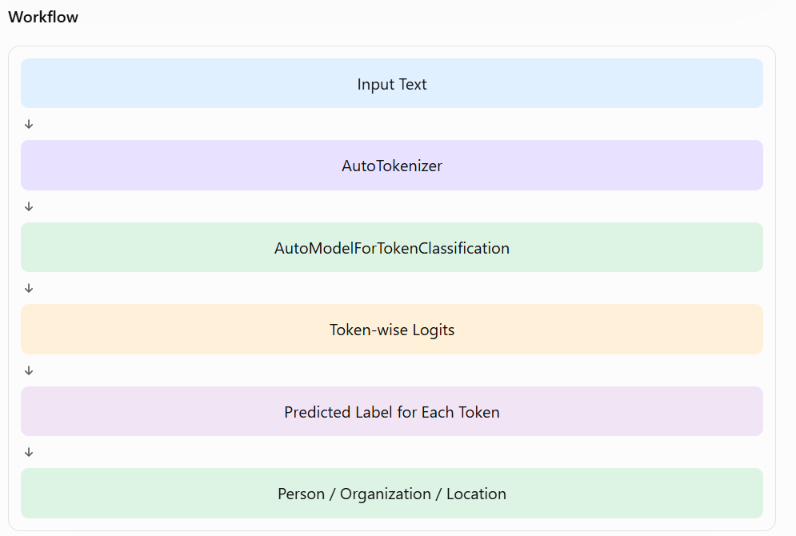

In [3]:

from transformers import AutoTokenizer, AutoModelForTokenClassification
import torch

model_name = "dslim/bert-base-NER"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load token classification model
model = AutoModelForTokenClassification.from_pretrained(model_name)

# Input text
text = "Nanda works at Google in India."

# Tokenization
inputs = tokenizer(text, return_tensors="pt")

# Perform inference
with torch.no_grad():
    outputs = model(**inputs)

# Get raw scores
logits = outputs.logits

# Get predicted labels
predictions = torch.argmax(logits, dim=-1)

# Convert token IDs into tokens
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

# Display token and predicted label
for token, prediction in zip(tokens, predictions[0]):
    label = model.config.id2label[prediction.item()]
    print(token, ":", label)


Some weights of the model checkpoint at dslim/bert-base-NER were not used when initializing BertForTokenClassification: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


[CLS] : O
Nan : B-PER
##da : B-PER
works : O
at : O
Google : B-ORG
in : O
India : B-LOC
. : O
[SEP] : O


In [ ]:
The exact tokenization and predictions may vary.
Label	Meaning
B-PER	Beginning of a person's name
I-PER	Inside a person's name
B-ORG	Beginning of an organization
B-LOC	Beginning of a location
O	Not a named entity

Understand the output:
- Nanda → Person
- Google → Organization
- India → Location
- works, at, in → Not named entities
Important: B- means the beginning of an entity, I- means inside an entity, and O means outside any entity.

Also, the example uses a model trained for NER, so its predictions are model-generated and are not guaranteed to be correct for every sentence.

# 5. AutoModelForCausalLM

**What is AutoModelForCausalLM?**

`AutoModelForCausalLM` is a Hugging Face class used to generate text by predicting the next token based on previously available tokens.

Causal Language Models generate text from left to right, using the previous tokens as context.

**Purpose:**

- Generate text automatically.
- Predict the next token.
- Complete incomplete sentences.
- Generate paragraphs.
- Build text-generation applications.

**Example Tasks:**

- Text Generation
- Sentence Completion
- Story Generation
- Conversational Text Generation

**Model:**

`distilgpt2`

**Input:**

A starting sentence or prompt converted into token IDs.

**Output:**

- `logits`: Raw scores for possible next tokens.
- `generated_tokens`: Newly generated token IDs.
- `generated_text`: Final generated text.

**Important:** Causal Language Models predict the next token using previous tokens. They do not look at future tokens when predicting the next token.

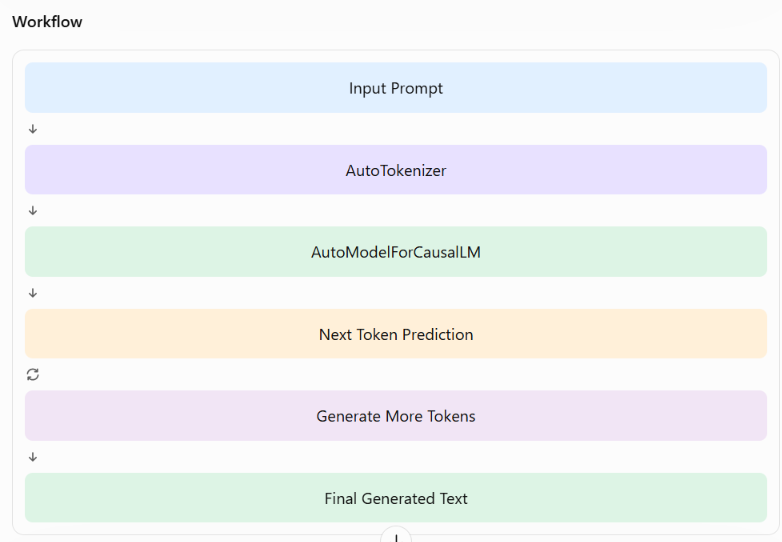

In [4]:

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "distilgpt2"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load causal language model
model = AutoModelForCausalLM.from_pretrained(model_name)

# Input prompt
text = "Artificial Intelligence is"

# Tokenization
inputs = tokenizer(text, return_tensors="pt")

# Perform text generation
with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=30,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

# Decode generated tokens
generated_text = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("Generated Text:", generated_text)


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

C:\Users\nanda\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\nanda\.cache\huggingface\hub\models--distilgpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Generated Text: Artificial Intelligence is a new technology that is being developed by the University of California at Berkeley.

















In [ ]:
Understand the output:
- Input prompt: The starting text provided to the model.
- Next-token prediction: The model predicts the next token based on previous tokens.
- max_new_tokens=30: Generates up to 30 additional tokens.
- generated_text: Contains the original prompt followed by the generated text.
Important: outputs from generate() contains generated token IDs, not the final readable text. We use tokenizer.decode() to convert those token IDs into text.

# 6. AutoModelForSeq2SeqLM

**What is AutoModelForSeq2SeqLM?**

`AutoModelForSeq2SeqLM` is a Hugging Face class used for sequence-to-sequence (Seq2Seq) tasks.

It takes an input sequence of text and generates a new output sequence of text.

Unlike causal language models, which generate text from left to right using previous tokens, Seq2Seq models use an encoder-decoder architecture.

**Purpose:**

- Convert one sequence of text into another.
- Translate text between languages.
- Summarize long documents.
- Generate answers from input text.
- Perform text-to-text tasks.

**Example Tasks:**

- Machine Translation
- Text Summarization
- Text-to-Text Generation
- Question Answering

**Model:**

`google/flan-t5-small`

**Input:**

A text instruction or input sentence converted into token IDs.

**Output:**

- Encoder representations: Contextual information extracted from the input.
- Decoder output: Generated output token IDs.
- Generated text: Final readable response.

**Important:** Seq2Seq models use an encoder to understand the input and a decoder to generate the output sequence.

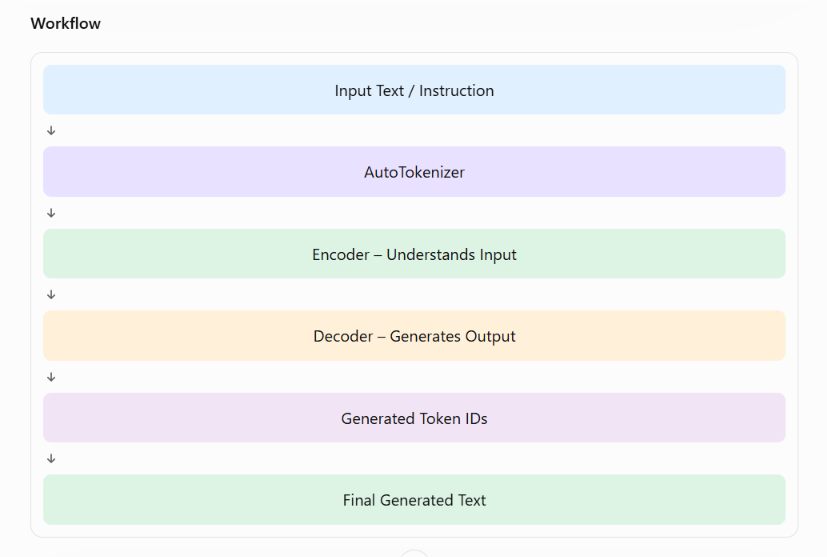

In [ ]:

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

model_name = "google/flan-t5-small"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load Seq2Seq model
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

# Input instruction
text = "Translate English to French: How are you?"

# Tokenization
inputs = tokenizer(text, return_tensors="pt")

# Perform inference
with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=30
    )

# Decode generated tokens
generated_text = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("Generated Text:", generated_text)
